In [9]:
# --- setup --------------------------------------------------------
import sys
from pathlib import Path

# Project paths on your two systems
PROJECT_PATHS = [
    Path(r"D:\Projects\done\eth_bot\eth_bot_v2"),
    Path(r"D:\Sachin Chakrawarti\eth_bot\eth_bot_v2"),
]

# Automatically select the project path that exists
for project_path in PROJECT_PATHS:
    if project_path.exists():
        sys.path.insert(0, str(project_path))
        break
else:
    raise FileNotFoundError(
        "eth_bot_v2 project directory was not found on this system."
    )

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

DB = Path(r"D:\Projects\done\eth_bot\eth_bot_v2\database\market.db")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (12, 4)

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from analysis.loader import load_ohlcv
from analysis.indicators import add_all
from analysis import stats


In [10]:
DB = Path(r"D:\Sachin Chakrawarti\eth_bot\eth_bot_v2") / "database" / "market.db"

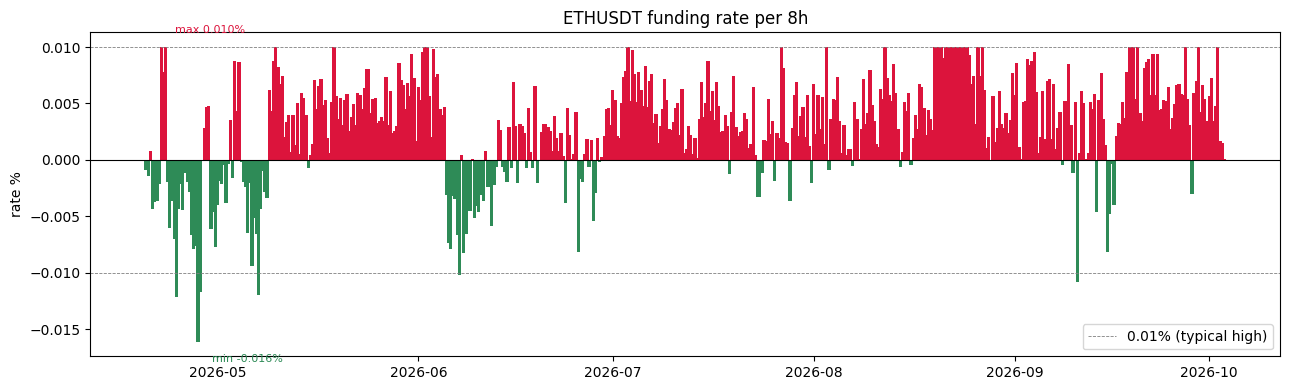

rows: 500
mean: +0.00303%
std : 0.00452%
max : +0.01000%  on 2026-04-22
min : -0.01610%  on 2026-04-28


In [11]:
# --- funding rate series -----------------------------------------
fr = sql("SELECT ts, rate FROM funding_rate ORDER BY ts")
fr["date"] = pd.to_datetime(fr.ts, unit="ms")
fr = fr.set_index("date").drop(columns="ts")

# convert to percent for readability
fr["rate_pct"] = fr["rate"] * 100

fig, ax = plt.subplots(figsize=(13, 4))
colors = ["crimson" if v > 0 else "seagreen" for v in fr["rate_pct"]]
ax.bar(fr.index, fr["rate_pct"], width=0.5, color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(0.01, ls="--", color="gray", lw=0.6, label="0.01% (typical high)")
ax.axhline(-0.01, ls="--", color="gray", lw=0.6)
ax.set_title("ETHUSDT funding rate per 8h")
ax.set_ylabel("rate %")
ax.legend()

# annotate extremes
hi = fr["rate_pct"].idxmax()
lo = fr["rate_pct"].idxmin()
ax.annotate(f"max {fr.loc[hi,'rate_pct']:.3f}%",
            xy=(hi, fr.loc[hi,'rate_pct']),
            xytext=(10, 10), textcoords="offset points",
            fontsize=8, color="crimson")
ax.annotate(f"min {fr.loc[lo,'rate_pct']:.3f}%",
            xy=(lo, fr.loc[lo,'rate_pct']),
            xytext=(10, -15), textcoords="offset points",
            fontsize=8, color="seagreen")

plt.tight_layout()
plt.show()

print(f"rows: {len(fr)}")
print(f"mean: {fr['rate_pct'].mean():+.5f}%")
print(f"std : {fr['rate_pct'].std():.5f}%")
print(f"max : {fr['rate_pct'].max():+.5f}%  on {hi.date()}")
print(f"min : {fr['rate_pct'].min():+.5f}%  on {lo.date()}")

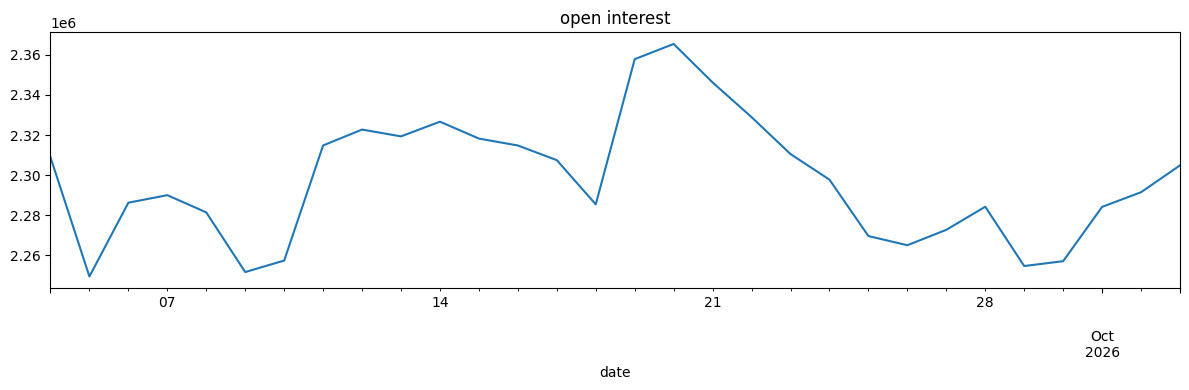

In [12]:
# --- open interest -----------------------------------------------
oi = sql("SELECT ts, oi, oi_value FROM open_interest ORDER BY ts")
oi["date"] = pd.to_datetime(oi.ts, unit="ms")
oi = oi.set_index("date")
oi.oi.plot(title="open interest")
plt.tight_layout()
plt.show()

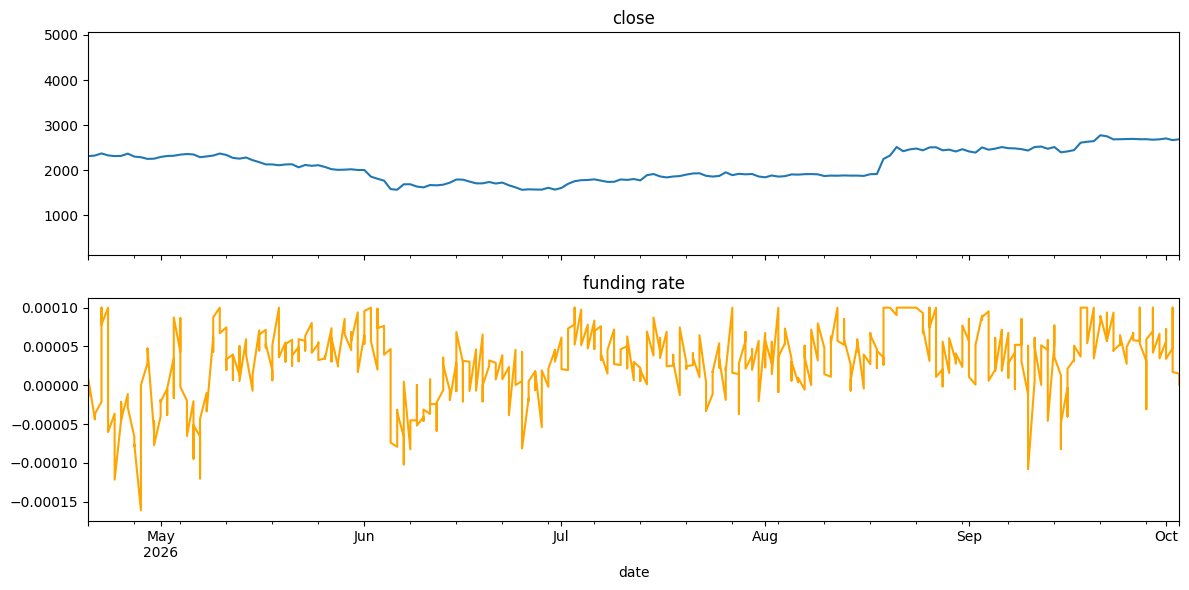

In [13]:
# --- price + funding overlay -------------------------------------
px = load_ohlcv().close
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
px.plot(ax=ax[0], title="close")
fr.rate.plot(ax=ax[1], color="orange", title="funding rate")
plt.tight_layout()
plt.show()